# 01. Titanic：データを眺めて、最初の提出まで

**このノートのゴール**
1. データを読み込んで「何が入っているか」を把握する
2. 簡単なモデルを作り、**正しく評価する**（ここが一番大事）
3. Kaggle に提出するファイルを作る

**課題の中身**：乗客の情報（性別・年齢・客室クラスなど）から、その人が**生き残ったか（Survived = 1）、亡くなったか（0）**を当てる。
こういう「2択を当てる問題」を **二値分類（binary classification）** と呼びます。

> 読み方：各コードセルの上の説明 → コード → 下の出力、の順に見てください。
> セルを選んで Shift+Enter で、上から順に実行できます。

## 1. 道具を読み込む

Python は「ライブラリ」と呼ばれる道具箱を `import` して使います。

| ライブラリ | 役割 |
|---|---|
| `pandas` | 表データ（Excel のようなもの）を扱う。ML で一番よく使う |
| `numpy` | 数値計算 |
| `matplotlib` / `seaborn` | グラフを描く |
| `sklearn`（scikit-learn） | 機械学習のモデルと評価の道具 |

`import pandas as pd` は「pandas を `pd` という短い名前で使う」という意味です。業界の慣習なので、どのコードでもこの名前で出てきます。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. データを読み込む

`pd.read_csv(パス)` で CSV ファイルを読み込むと、**DataFrame**（データフレーム）という表の形になります。

- `train`：答え（Survived）付きのデータ。**これで学習する**
- `test`：答えが隠されたデータ。**これを予測して提出する**

`変数名 = 値` は「右側の結果に左側の名前をつけて取っておく」という意味です。

In [2]:
DATA_DIR = "../data/titanic"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

print("train:", train.shape)  # (行数, 列数)
print("test :", test.shape)

train: (891, 12)
test : (418, 11)


`f"..."` は **f文字列**。`{}` の中に変数を埋め込めます。`.shape` は表の (行数, 列数) です。

test は列が 1 つ少ない（11列）ことに注目してください。**Survived 列が隠されている**からです。

`.head()` で先頭 5 行を見てみます。

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**列の意味**

| 列 | 意味 |
|---|---|
| PassengerId | 乗客の通し番号（予測には使わない） |
| **Survived** | **生存 1 / 死亡 0（当てたい答え＝目的変数）** |
| Pclass | 客室クラス（1 = 一等、2 = 二等、3 = 三等） |
| Name | 名前 |
| Sex | 性別 |
| Age | 年齢 |
| SibSp | 一緒に乗った兄弟・配偶者の数 |
| Parch | 一緒に乗った親・子の数 |
| Ticket | チケット番号 |
| Fare | 運賃 |
| Cabin | 客室番号 |
| Embarked | 乗船した港（C / Q / S） |

予測に使う列を **特徴量（feature）**、当てたい列を **目的変数（target）** と呼びます。

## 3. データの「穴」を確認する

実データには必ず **欠損値（空欄）** があります。多くのモデルは空欄があると動かないので、最初に確認します。

`.isnull()` で「空欄か？」を True/False にし、`.sum()` で列ごとに数えます。このように `.` でつないで処理を重ねる書き方を **メソッドチェーン** と呼び、pandas では頻出です。

In [4]:
pd.DataFrame({
    "train の欠損数": train.isnull().sum(),
    "test の欠損数": test.isnull().sum(),
})

,train の欠損数,test の欠損数
Age,177,86.0
Cabin,687,327.0
Embarked,2,0.0
Fare,0,1.0
Name,0,0.0
Parch,0,0.0
PassengerId,0,0.0
Pclass,0,0.0
Sex,0,0.0
SibSp,0,0.0


**読み取れること**
- **Age**：train の約 2 割が空欄 → 何かで埋める必要あり
- **Cabin**：ほぼ空欄（687 / 891）→ 今回は使わない
- **Embarked**：train に 2 件だけ空欄
- **Fare**：test に 1 件だけ空欄（train にはない。**test にだけ起こる問題**もある、という教訓）

## 4. 何が生死を分けたか、を見る（EDA）

モデルを作る前にデータを眺めて傾向をつかむ作業を **EDA（探索的データ分析）** と呼びます。
AI にモデルを書かせる時代でも、**ここで得た感覚が「AI の出した結果がおかしい」と気づく力になります**。

まず全体の生存率。Survived は 0/1 なので、平均（`.mean()`）がそのまま生存率になります。

In [5]:
print(f"全体の生存率: {train['Survived'].mean():.1%}")

全体の生存率: 38.4%


`train['Survived']` は「Survived 列を取り出す」。`:.1%` は「小数第1位までのパーセント表示」という書式指定です。

次に **性別ごと・客室クラスごと** の生存率。`.groupby(列)` は「その列の値ごとにグループに分ける」操作で、Excel のピボットテーブルに相当します。

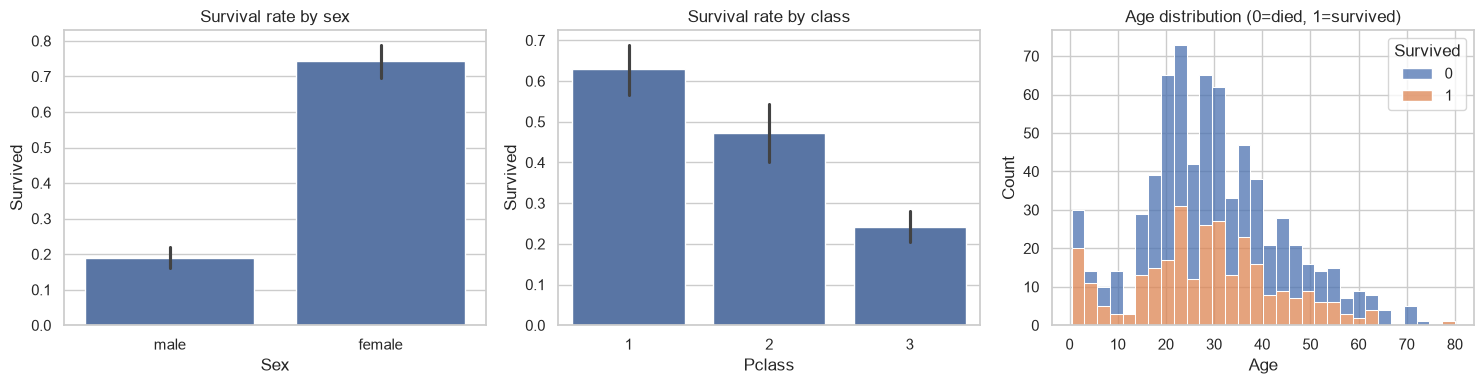

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=train, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")

sns.barplot(data=train, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survival rate by class")

sns.histplot(data=train, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[2])
axes[2].set_title("Age distribution (0=died, 1=survived)")

plt.tight_layout()
plt.show()

train.groupby(["Sex", "Pclass"])["Survived"].mean().unstack().round(2)

**読み取れること**
- **女性の生存率は約 74%、男性は約 19%**。圧倒的に効く特徴量（「女性と子どもを先に」）
- 一等客室ほど生存率が高い。三等の女性は一等・二等の女性より明らかに低い
- 年齢では、幼い子どもの生存率が高め

ここから、**「女性なら生存、男性なら死亡」と答えるだけでもかなり当たる**ことが予想できます。
実は Kaggle が配っている `gender_submission.csv` がまさにそれで、スコアは約 0.766（76.6% 正解）です。
これを **ベースライン（最低ライン）** と考え、モデルがこれを超えられるかを見ていきます。

## 5. モデルが読める形に整える（前処理）

機械学習モデルは **数値しか扱えず、空欄も苦手** です。そこで：

1. `Sex` の male/female を 0/1 の数値に変える
2. `Embarked` の C/Q/S を、それぞれ「その港か？」の 0/1 列に分ける（**ワンホットエンコーディング**）
3. 空欄を埋める（Age・Fare は中央値、Embarked は最頻値）

**大事な注意**：埋める値（中央値など）は **train から計算して、test にも同じ値を使う** こと。
test の情報を使って前処理を決めると、本番では手に入らない情報を使ったことになります（**リーク**の一種。後の回で詳しく扱います）。

同じ処理を train と test の両方にかけたいので、処理を **関数** にまとめます。
`def 関数名(引数):` で定義し、`return` で結果を返します。

In [7]:
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

# 埋める値は train だけから決める
fill_values = {
    "Age": train["Age"].median(),
    "Fare": train["Fare"].median(),
    "Embarked": train["Embarked"].mode()[0],  # 最頻値
}
print("欠損の穴埋めに使う値:", fill_values)


def preprocess(df):
    X = df[FEATURES].copy()                       # 使う列だけ取り出す（元データは壊さない）
    X = X.fillna(fill_values)                     # 空欄を埋める
    X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
    X = pd.get_dummies(X, columns=["Embarked"], dtype=int)  # C/Q/S を 0/1 の3列に
    return X


X_train = preprocess(train)
y_train = train["Survived"]
X_test = preprocess(test)

X_train.head()

欠損の穴埋めに使う値: {'Age': np.float64(28.0), 'Fare': np.float64(14.4542), 'Embarked': 'S'}


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,3,0,35.0,0,0,8.0500,0,0,1


慣習として、**特徴量の表を `X`（大文字）、答えを `y`（小文字）** と書きます。どの ML コードでもこの名前が出てきます。

すべて数値になり、空欄もなくなりました。

## 6. モデルを作り、**正しく評価する**

モデルには **ランダムフォレスト** を使います。「決定木（Yes/No の質問を重ねて答えを出すフローチャート）」をたくさん作り、多数決で答えるモデルです。表データで手堅く使える定番です。

scikit-learn のモデルは、どれも同じ 2 ステップで使えます。
- `model.fit(X, y)`：学習する
- `model.predict(X)`：予測する

### まず、わざと「間違った評価」をしてみる

学習に使ったデータで、そのまま正解率を測ってみます。

In [8]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=300, random_state=42)
model.fit(X_train, y_train)

train_acc = (model.predict(X_train) == y_train).mean()
print(f"学習データでの正解率: {train_acc:.1%}")

学習データでの正解率: 98.0%


約 98% と、すごく良く見えます。**でも、これは信用できない数字です。**

学習に使ったデータで測るのは、**答えを見ながら解いた問題でテストの点数を測るようなもの**です。
モデルは学習データを「丸暗記」できてしまうので、未知のデータ（= test）では点数がずっと下がります。
この丸暗記状態を **過学習（overfitting）** と呼びます。

### 正しい評価：交差検証（Cross Validation, CV）

train を 5 つに分け、「4 つで学習 → 残り 1 つで採点」を 5 回繰り返して平均します。
**採点に使うデータは、そのモデルの学習に一度も使っていない**ので、未知のデータでの実力に近い数字が出ます。

```
1回目: [採点][学習][学習][学習][学習]
2回目: [学習][採点][学習][学習][学習]
 ...
5回目: [学習][学習][学習][学習][採点]
```

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
print("各回の正解率:", scores.round(3))
print(f"CV 平均: {scores.mean():.1%}  (ばらつき ±{scores.std():.1%})")

各回の正解率: [0.844 0.815 0.775 0.815 0.843]
CV 平均: 81.8%  (ばらつき ±2.5%)


**98% → 約 81%** に下がりました。こちらが本当の実力に近い数字です。

`StratifiedKFold` は「各グループの生存者の割合がそろうように分ける」分け方です（分類問題ではこれが基本）。

### ここがこのノートで一番大事なポイント

> **AI に「モデルを作って」と頼んで「正解率 98% です！」と返ってきたら、まず「それ、何のデータで測った？」と聞く。**

Kaggle でも実務でも、失敗の多くはモデルの選び方ではなく **評価の仕方の間違い** から起きます。
評価が正しければ、改善が本物かどうかを判断できます。評価が間違っていると、何をやっても判断できません。

### ベースラインと比べる

「女性なら生存」だけのルールも、同じ train で測ってみます。

In [10]:
baseline_acc = ((train["Sex"] == "female").astype(int) == y_train).mean()
print(f"ベースライン（女性なら生存）: {baseline_acc:.1%}")
print(f"ランダムフォレスト (CV)      : {scores.mean():.1%}")

ベースライン（女性なら生存）: 78.7%
ランダムフォレスト (CV)      : 81.8%


ベースライン（約 79%）よりは上ですが、差は 3 ポイントほど。
**性別の情報だけで、ほとんど説明できてしまう**ということです。ここからどう伸ばすかが、次回以降のテーマです。

### モデルは何を重視したか

ランダムフォレストは、各特徴量がどれだけ予測に役立ったか（**特徴量の重要度**）を出せます。

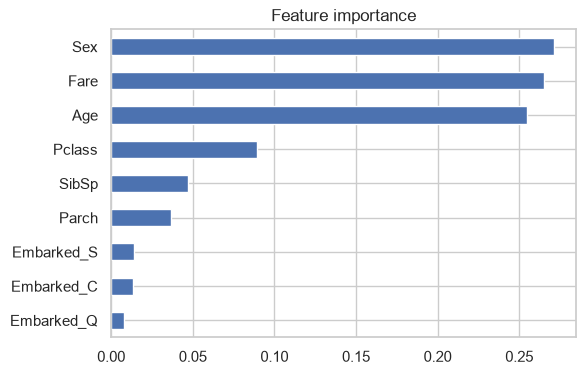

In [11]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
importances.plot.barh(figsize=(6, 4), title="Feature importance")
plt.show()

Sex・Fare・Age が上位に来ます。EDA で見た傾向と合っているので、モデルの判断が「筋が通っている」と確認できます。
（運賃・年齢は値の種類が多いので、この指標では高めに出やすい、というクセもあります。）

## 7. 提出ファイルを作る

train **全体** で学習し直したモデル（6 の最初のセルで `fit` 済み）で test を予測し、
Kaggle が指定する形式（`PassengerId, Survived` の 2 列）の CSV に保存します。

In [12]:
import os

os.makedirs("../submissions", exist_ok=True)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": model.predict(X_test),
})
submission.to_csv("../submissions/01_random_forest.csv", index=False)

print(submission.shape)
print(f"予測した生存率: {submission['Survived'].mean():.1%}  (train の実際の生存率: {y_train.mean():.1%})")
submission.head()

(418, 2)
予測した生存率: 36.6%  (train の実際の生存率: 38.4%)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,0


**提出前の確認（毎回やる習慣にする）**
- 行数が test と同じ 418 行か
- 列名が `PassengerId, Survived` か
- 予測の生存率が train の生存率から大きく外れていないか（全部 0 になっている、などのバグに気づける）

提出はターミナルから：
```
uv run kaggle competitions submit -c titanic -f submissions/01_random_forest.csv -m "01 random forest baseline"
```

**予想**：CV が約 81% だったので、Kaggle のスコア（Public LB）もそれに近い 0.77〜0.80 程度になるはずです。
CV と LB がだいたい一致するかどうかが、「評価が正しくできているか」の確認になります。

## まとめ：今日覚える言葉

| 言葉 | 意味 |
|---|---|
| 特徴量 / 目的変数 | 予測に使う列 / 当てたい列（`X` / `y`） |
| 欠損値 | 空欄。埋めるか、その列を使わない |
| EDA | モデルの前にデータを眺めて傾向をつかむこと |
| ベースライン | 一番単純な方法のスコア。これを超えないモデルには意味がない |
| 過学習 | 学習データを丸暗記して、未知のデータに弱くなる状態 |
| 交差検証（CV） | 学習に使っていないデータで採点を繰り返す、正しい評価方法 |
| リーク | 本番では使えない情報が学習や評価に紛れ込むこと |

**次回の予告**：名前の「Mr. / Mrs. / Miss / Master」や家族の人数から新しい特徴量を作り（**特徴量エンジニアリング**）、CV が本当に上がるかを確かめます。